# The leakage-safe fit of the monotone scorecard, read back from the Taiwan cards

**Question:** Which parts of the C01 fit may see which cards, and does the fitted scorecard earn its thirteen variables against a one-variable baseline on 9,000 cards that no fitting step has seen?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- state the leakage-safe design of the C01 fit: what is split off, what each slice may be used for and what is fitted on the training slice only;
- check on the committed counts that the learned bins respect their constraints (at least 5% of the cards per bin, a default rate that follows its direction);
- place raw cards into the learned bins by hand and rebuild their score as a sum of points, with no model object;
- compare the scorecard with a one-variable baseline on 9,000 held-out cards with the engine's AUC, KS, DeLong, chi-square and level tests.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.validation.calibration import pd_brier, pd_chi2_grades, pd_ece, pd_jeffreys
from riskvalidation.validation.discrimination import auc_with_variance, disc_auc, disc_delong, disc_ks

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The case is the one of notebook 01: C01, the UCI Taiwan credit-card file (Yeh, 2009; owner: UCI Machine Learning Repository; CC BY 4.0, licence class `mirror-allowed`; https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), 30,000 cards. The fit itself runs in the pipeline (`data-pipeline/pipeline/model/scorecard.py`, with `optbinning`, `statsmodels` and `scikit-learn`) on the raw file, which lives outside the repository under the data root. This notebook reads what the fit committed, so it needs neither the raw file nor those libraries:

- `data/derived/C01/models-taiwan.json`: the split, the variables with their constraints, the learned cut points, the coefficients and the table of points with the training counts of every bin.
- `data/derived/C01/holdout.json`: the 50-card sample with raw inputs, points, score and PD; the CAP curve, ROC curve, grade table and reliability bins of every model on the 9,000 held-out cards; and the committed test rows.

The next cell loads both files.

In [2]:
# Load the two committed files of case C01 (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
models = json.loads((derived / "models-taiwan.json").read_text(encoding="utf-8"))
holdout = json.loads((derived / "holdout.json").read_text(encoding="utf-8"))
fit = models["fit"]
card = next(m for m in models["model"] if m["id"] == "P1-scorecard")["details"]
table = card["points_table"]
sample = holdout["outputs"]["sample"]
rungs = holdout["outputs"]["rungs"]
policy = rv.default_policy()
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "none"}
rows_total = sum(fit["split"][s]["n"] for s in ("train", "calibration", "holdout"))
print("seed of the bake:", fit["seed"], "| rows in the file:", rows_total)
print("baked by riskvalidation", models["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

seed of the bake: 42 | rows in the file: 30000
baked by riskvalidation 1.0.1 | installed 1.0.1


## Method

### Step 1: what may see what, the leakage-safe split

The research rules for every scoring fit (dossier 04 of the product's research basis, "universal leakage rules") say that every transform is **fitted on the training slice only** (binning, WoE, imputation, scaling, variable selection), that a calibration map is fitted on a **separate** calibration slice and never on the test slice, and that nothing is resampled before calibration is measured. Case C01 applies them with one stratified split with a fixed seed: 56% of the cards to fit, 14% to calibrate the challengers of notebook 06, and a locked holdout of 30% that no fitting step has seen. The scorecard itself uses the training slice only. The cell draws the size and the default rate of each slice from the fit record.

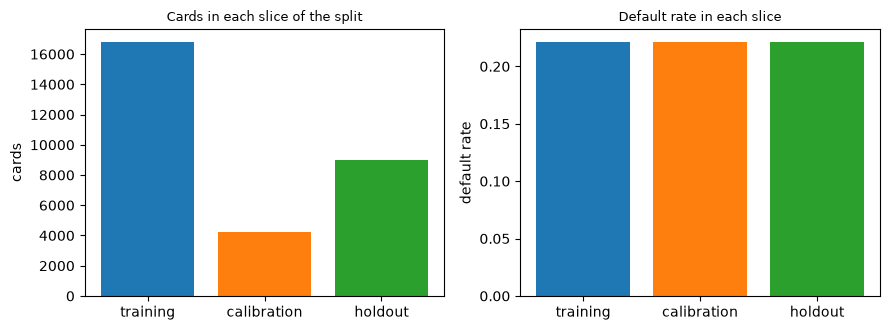

cards in each slice: [16800, 4200, 9000]
share of the cards in each slice: [0.56, 0.14, 0.3]
spread of the default rate across the slices: 3e-05


In [3]:
# Draw the three slices of the split with their default rates
split = fit["split"]
slices = ["train", "calibration", "holdout"]
cards = [split[s]["n"] for s in slices]
rates = [split[s]["default_rate"] for s in slices]
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.4))
left.bar(["training", "calibration", "holdout"], cards, color=["tab:blue", "tab:orange", "tab:green"])
left.set_ylabel("cards")
left.set_title("Cards in each slice of the split", fontsize=9)
right.bar(["training", "calibration", "holdout"], rates, color=["tab:blue", "tab:orange", "tab:green"])
right.set_ylabel("default rate")
right.set_title("Default rate in each slice", fontsize=9)
fig.tight_layout()
plt.show()
print("cards in each slice:", cards)
print("share of the cards in each slice:", [round(c / sum(cards), 2) for c in cards])
print("spread of the default rate across the slices:", round(max(rates) - min(rates), 5))

The left panel shows the three slices at 16,800, 4,200 and 9,000 cards, the shares 0.56, 0.14 and 0.3 of the 30,000 in the file. The right panel is the point of stratifying: the three default rates are the same 22.1%, and their spread is 3e-05, so the holdout is a fair sample of the population the scorecard was fitted on and a gap between training and holdout performance cannot be blamed on a different mix of good and bad cards. What the figure cannot show is that nothing leaked: that is a property of the fitting path, guarded by a test in the pipeline (`tests/test_leakage.py`, shown in notebook 07), and visible here only through the counts of the next step.

### Step 2: the learned bins and their constraints

Each variable carries a **monotone constraint**, the direction in which its default rate may move along the bins: ascending for the months of delay (more delay, more default), descending for the credit limit and the payment amounts, free for the rest. A monotone binning keeps the scorecard explainable, because a larger limit can never buy a worse score. The fit also demands that every bin holds at least 5% of the cards, so that its default rate rests on enough defaults. Both properties can be checked on the counts the points table commits, and the same counts show where the bins were learned: they add up to the 16,800 training cards for every variable. The cell computes the share of the smallest bin and the direction of the default rate for the 13 kept variables, and plots the smallest shares beside the default rate along the bins of two variables.

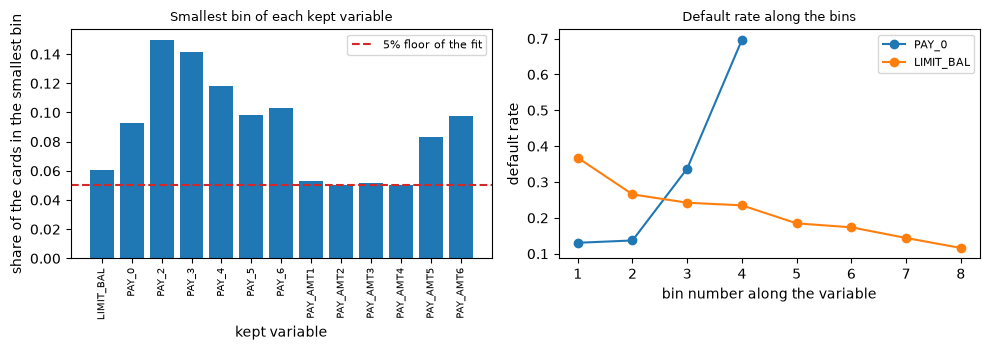

variables whose smallest bin holds at least 5%: 13 of 13
variables whose default rate follows its constraint: 13 of 13


In [4]:
# Smallest bin share and direction of the default rate of each kept variable, from the committed counts
constraint = {v["name"]: v["monotone"] for v in fit["features"]}
smallest, follows = {}, {}
for name in card["features"]:
    rows = [r for r in table if r["feature"] == name and r["count"] > 0]
    steps = np.diff([r["event_rate"] for r in rows])
    smallest[name] = min(r["count"] for r in rows) / sum(r["count"] for r in rows)
    follows[name] = bool((steps >= 0).all() if constraint[name] == 1 else (steps <= 0).all())
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(list(smallest), list(smallest.values()), color="tab:blue")
left.axhline(0.05, color="tab:red", linestyle="--", label="5% floor of the fit")
left.tick_params(axis="x", labelrotation=90, labelsize=7)
left.set_xlabel("kept variable")
left.set_ylabel("share of the cards in the smallest bin")
left.set_title("Smallest bin of each kept variable", fontsize=9)
left.legend(fontsize=8)
for name in ("PAY_0", "LIMIT_BAL"):
    rows = [r for r in table if r["feature"] == name and r["count"] > 0]
    right.plot(range(1, len(rows) + 1), [r["event_rate"] for r in rows], marker="o", label=name)
right.set_xlabel("bin number along the variable")
right.set_ylabel("default rate")
right.set_title("Default rate along the bins", fontsize=9)
right.legend(fontsize=8)
fig.tight_layout()
plt.show()
big_enough = sum(v >= 0.05 for v in smallest.values())
print("variables whose smallest bin holds at least 5%:", big_enough, "of", len(smallest))
print("variables whose default rate follows its constraint:", sum(follows.values()), "of", len(follows))

All 13 variables keep a smallest bin above the red 5% line (the narrowest is just over 5%), and all 13 default rates follow their constraint. The right panel shows the two directions: the rate of `PAY_0` climbs from about 13% to about 70% over its four bins, while the rate of `LIMIT_BAL` falls over eight bins as the limit grows. The figure does not show that the cut points are the best possible, only that they obey the rules; the choice of the cut points is the optimisation of the pipeline (Navas-Palencia, 2020).

### Step 3: place raw cards into the bins and add the points

A scorecard is auditable because its score needs no model object. For each of the 13 variables the next cell counts the cut points at or below the card's raw value (`numpy.searchsorted` with `side="right"`, which is exactly the half-open rule of a bin), reads the points of that row of the table, and adds the 13 numbers. The 50 cards of the holdout sample come with their raw inputs, so the sum can be set beside the score the pipeline stored. The cell prints how many of the 650 point cells and of the 50 scores agree, and draws the histogram of the rebuilt scores, defaulters stacked on top of the others.

point cells equal to the stored ones: 650 of 650
scores equal to the stored ones: 50 of 50
AUC of the integer score alone, 50 cards: 0.7781


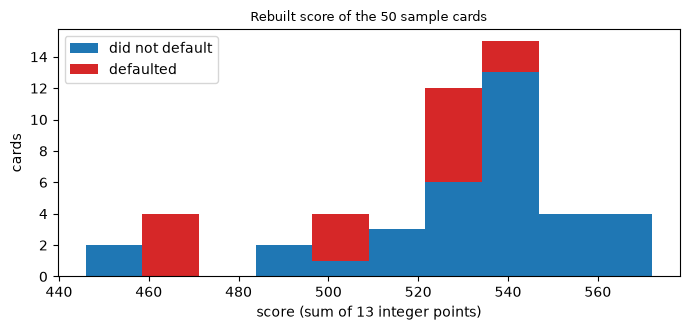

In [5]:
# Place the raw inputs of the 50 cards in the learned bins, add their points and compare with the stored score
inputs = sample["inputs"]
columns = []
for name in card["features"]:
    rows = [r for r in table if r["feature"] == name]
    cuts = card["bins"][name]["splits"]
    index = np.searchsorted(cuts, np.array(inputs[name], dtype=float), side="right")
    columns.append([rows[i]["points"] for i in index])
points = np.array(columns).T
score = points.sum(axis=1)
y50 = np.array(sample["targets"])
same_points = int((points == np.array(sample["scorecard_points"])).sum())
same_score = int((score == np.array(sample["scorecard_score"])).sum())
print("point cells equal to the stored ones:", same_points, "of", points.size)
print("scores equal to the stored ones:", same_score, "of", len(score))
auc_score = disc_auc(-score.astype(float), y50, policy=policy, model_id="P1-scorecard")
print("AUC of the integer score alone, 50 cards:", round(auc_score.metric, 4))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist([score[y50 == 0], score[y50 == 1]], bins=10, stacked=True, color=["tab:blue", "tab:red"],
        label=["did not default", "defaulted"])
ax.set_xlabel("score (sum of 13 integer points)")
ax.set_ylabel("cards")
ax.set_title("Rebuilt score of the 50 sample cards", fontsize=9)
ax.legend()
fig.tight_layout()
plt.show()

All 650 point cells and all 50 scores agree with what the pipeline stored: a score is nothing but the sum of 13 table lookups. The histogram shows what the sum is for. Ranked by the integer score alone, with no PD and no model, the engine gives an AUC of 0.7781 on these cards. Cards that defaulted (red) tend to sit at the low end of the score range, while the high scores are mostly blue. With 15 defaulters among 50 cards the picture is a sketch, not a measurement, and the next steps put numbers on it.

### Step 4: what the logistic step decided

The logistic step fixed one coefficient per variable. Its effect on a card is the **spread of the points** of the variable: the points of its best bin minus the points of its worst bin, $\mathrm{Factor}\,|\beta_j|\,(\max_b \mathrm{WoE}_{j,b} - \min_b \mathrm{WoE}_{j,b})$. A variable with a wide spread can move the score of a card a lot; one with a narrow spread hardly matters. This is the scorecard's own reading of which variables drive the score, the number a credit officer would quote. The cell computes the spread from the committed table and draws it, widest first.

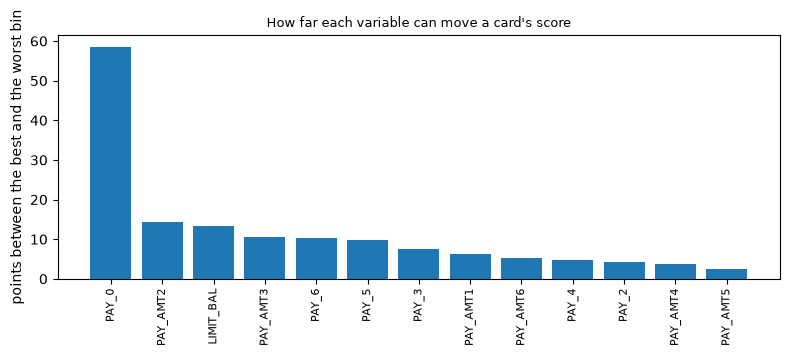

widest and narrowest spread: PAY_0 58.5 PAY_AMT5 2.6


In [6]:
# The spread of points of each variable, the best bin minus the worst, from the committed table
spread = {}
for name in card["features"]:
    pts = [r["points_raw"] for r in table if r["feature"] == name and r["count"] > 0]
    spread[name] = max(pts) - min(pts)
order = sorted(spread, key=lambda n: -spread[n])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(order, [spread[n] for n in order], color="tab:blue")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.set_ylabel("points between the best and the worst bin")
ax.set_title("How far each variable can move a card's score", fontsize=9)
fig.tight_layout()
plt.show()
print("widest and narrowest spread:", order[0], round(spread[order[0]], 1), order[-1], round(spread[order[-1]], 1))

`PAY_0` stands alone: 58.5 points between its best and worst bin, then a long tail down to `PAY_AMT5`, with 2.6. The next three (`PAY_AMT2`, `LIMIT_BAL` and `PAY_AMT3`) span between 10 and 14 points each, and the remaining variables less. So the scorecard is mostly a repayment-status model with modest corrections. This also says what a one-variable baseline can capture and what the other twelve variables must add.

### Step 5: the scorecard against a one-variable baseline, on the 50 cards

A fit is worth its complexity only if it beats something simpler. The simplest ranking on the sample is the raw value of `PAY_0` used alone, which stands for rung P0 of the ladder. The engine's `disc_auc` returns the AUC, the probability that a defaulter is ranked above a non-defaulter (Hanley and McNeil, 1982), and `disc_ks` the largest gap between the score distributions of defaulters and of the rest. `disc_delong` tests the difference of two AUCs measured on the same cards, whose estimates are correlated, with the covariance of the two curves (DeLong, DeLong and Clarke-Pearson, 1988): its statistic is the AUC difference over its standard error. The cell calls the three on the 50 cards.

In [7]:
# The engine on the 50 cards: the scorecard against the raw PAY_0 value used alone as a ranking
pd50 = np.array(sample["scorecard_pd"])
pay0_raw = np.array(inputs["PAY_0"], dtype=float)
auc_card = disc_auc(pd50, y50, policy=policy, model_id="P1-scorecard")
auc_one = disc_auc(pay0_raw, y50, policy=policy, model_id="P0-single")
ks_card = disc_ks(pd50, y50, policy=policy, model_id="P1-scorecard")
ks_one = disc_ks(pay0_raw, y50, policy=policy, model_id="P0-single")
duel = disc_delong(pd50, pay0_raw, y50, policy=policy, model_id="P1-scorecard")
print("AUC on 50 cards (scorecard, PAY_0 alone):", round(auc_card.metric, 4), round(auc_one.metric, 4))
print("KS on 50 cards (scorecard, PAY_0 alone):", round(ks_card.metric, 4), round(ks_one.metric, 4))
print("DeLong, scorecard against PAY_0 alone: z, p, light:", round(duel.statistic, 2), round(duel.p_value, 4))
print(LIGHT[duel.light.value])

AUC on 50 cards (scorecard, PAY_0 alone): 0.7752 0.599
KS on 50 cards (scorecard, PAY_0 alone): 0.5048 0.2095
DeLong, scorecard against PAY_0 alone: z, p, light: 2.55 0.0107
amber


On the 50 cards the scorecard reaches an AUC of 0.7752 and a KS of 0.5048, while `PAY_0` alone reaches 0.599 and 0.2095. The DeLong statistic is 2.55 with a p-value of 0.0107, which the default policy colours amber. The scorecard beats the baseline here, and the engine says that this is unlikely to be chance, even with only 15 defaulters. How wide the uncertainty is on each AUC is the next question: the AUC of a ranking measured on 50 cards is itself an estimate.

### Step 6: how sure is a 50-card AUC, and how good is the PD as a forecast

`auc_with_variance` returns the AUC with its variance and the counts of defaulters and non-defaulters, so that a normal 95% interval is the AUC plus or minus $1.96\sqrt{\widehat{\mathrm{Var}}}$. The PD of a scorecard is also a forecast of a 0/1 outcome, which `pd_brier` scores with the mean squared error (lower is better) and `pd_ece` with the expected calibration error, the weighted mean gap between the mean PD and the observed rate in bins. A constant PD equal to the sample default rate is the reference forecast every model must beat. The cell prints the intervals of both rankings and the two forecast scores.

In [8]:
# The AUC of each ranking on the 50 cards with its normal 95% interval, and the Brier score and ECE of the PD
auc_a, var_a, _, _ = auc_with_variance(pd50, y50)
auc_b, var_b, _, _ = auc_with_variance(pay0_raw, y50)
for label, a, v in (("P1", auc_a, var_a), ("PAY_0", auc_b, var_b)):
    print("95% interval of the AUC:", label, round(a - 1.96 * v ** 0.5, 3), round(a + 1.96 * v ** 0.5, 3))
brier_card = pd_brier(y50, pd50, policy=policy, model_id="P1-scorecard")
brier_flat = pd_brier(y50, np.full(len(y50), y50.mean()), policy=policy, model_id="P0-constant")
ece_card = pd_ece(y50, pd50, bins=5, policy=policy, model_id="P1-scorecard")
print("Brier score on 50 cards (scorecard, constant PD):", round(brier_card.metric, 4))
print(round(brier_flat.metric, 4))
print("ECE on 50 cards (scorecard):", round(ece_card.metric, 4))

95% interval of the AUC: P1 0.646 0.904
95% interval of the AUC: PAY_0 0.419 0.779
Brier score on 50 cards (scorecard, constant PD): 0.1897
0.21
ECE on 50 cards (scorecard): 0.1001


The interval of the scorecard's AUC runs from 0.646 to 0.904 and that of `PAY_0` alone from 0.419 to 0.779, so the two overlap on 50 cards; it is the paired DeLong test, not the overlap of the intervals, that carries the comparison. The Brier score is 0.1897 for the scorecard against 0.21 for the constant PD, a modest gain, and the ECE of 0.1001 on five bins of ten cards shows how little a 50-card sample can say about calibration. These numbers motivate moving to the 9,000 held-out cards.

### Step 7: the same comparison on 9,000 held-out cards

The 9,000 cards are not in the repository, but the holdout file commits, for every model, the CAP curve: the cumulative share of defaulters caught as the population is cut at 1% steps from the riskiest card. The cell rebuilds from those steps a vector of 9,000 risk values and outcomes (100 slices of 90 cards, the slices in decreasing order of risk) and hands it to the engine for the baseline and for the scorecard. Within a slice the order of the cards is lost, so the cards of a slice count as ties; the committed AUC of the same cards, computed by the pipeline on the cards themselves, is printed beside the engine's, and the ROC curves of the two models are drawn.

AUC and KS of the rebuilt 9000 cards: P0-single 0.6994 0.3573
AUC and KS of the rebuilt 9000 cards: P1-scorecard 0.7586 0.3956
AUC committed (P0, P1): 0.6917 0.7587


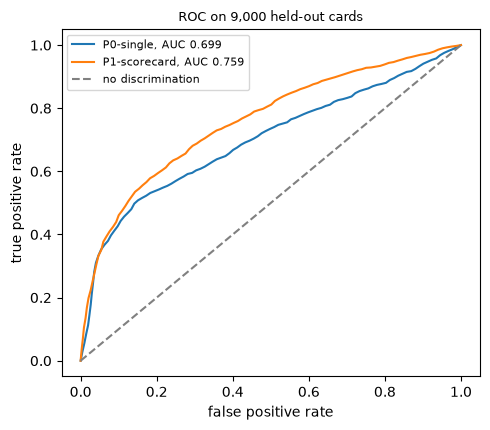

In [9]:
# Rebuild 9000 cards from the CAP steps of two models (100 slices of 90 cards) and run the engine on each
n_cards, n_defaults = holdout["outputs"]["n"], holdout["outputs"]["defaults"]
rebuilt = {}
for rung in ("P0-single", "P1-scorecard"):
    per_slice = np.rint(np.diff(np.array(rungs[rung]["cap"]["defaults"])) * n_defaults).astype(int)
    size = n_cards // len(per_slice)
    risk = np.repeat(np.arange(len(per_slice), 0, -1), size)
    flags = np.concatenate([np.r_[np.ones(d), np.zeros(size - d)] for d in per_slice])
    auc = disc_auc(risk, flags, policy=policy, model_id=rung)
    ks = disc_ks(risk, flags, policy=policy, model_id=rung)
    rebuilt[rung] = (auc.metric, ks.metric)
    print("AUC and KS of the rebuilt 9000 cards:", rung, round(auc.metric, 4), round(ks.metric, 4))
tests = [t for t in holdout["tests"] if t["test_id"] == "disc.auc" and t["segment"] == "portfolio"]
committed = {t["model_id"]: t["metric"] for t in tests}
print("AUC committed (P0, P1):", round(committed["P0-single"], 4), round(committed["P1-scorecard"], 4))
fig, ax = plt.subplots(figsize=(5, 4.4))
for rung in rebuilt:
    ax.plot(rungs[rung]["roc"]["fpr"], rungs[rung]["roc"]["tpr"], label=f"{rung}, AUC {rebuilt[rung][0]:.3f}")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="no discrimination")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("ROC on 9,000 held-out cards", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The engine returns an AUC of 0.7586 for the scorecard on the rebuilt cards against the committed 0.7587: treating the 90 cards of a slice as ties costs one ten-thousandth. For the one-variable baseline the rebuilt value, 0.6994, is above the committed 0.6917. The reason is visible in the ROC figure: the baseline takes only four distinct PD values, so its curve has long straight stretches where thousands of cards are tied, and cutting a tie block into slices lets the rebuilt vector order cards that the model cannot order. The rebuilt AUC is therefore reliable for a model with many distinct scores and optimistic for a model with few. The KS says the same as the AUC: 0.3956 for the scorecard against 0.3573. The scorecard's curve lies above the baseline's over most of the range, which is the visual meaning of the AUC gain.

### Step 8: ranking is not calibration

A better ranking does not guarantee better PDs. Two committed tables answer the second question for each model: the grade table, with the cards, defaults and mean PD of each grade of the master scale, and the reliability table, ten bins of 900 cards by PD. `pd_chi2_grades` tests all grades at once against their mean PDs (BCBS, 2005), and `pd_jeffreys` tests the portfolio level, one-sided, with the cards, the defaults and the mean PD. The cell runs both for the two models and draws the reliability curves: the mean PD of each bin against its observed default rate, with the diagonal as perfect calibration.

chi-square over grades, p and light: P0-single 0.5982 green
level test of the portfolio, Jeffreys p: P0-single 0.2645
chi-square over grades, p and light: P1-scorecard 0.0264 amber
level test of the portfolio, Jeffreys p: P1-scorecard 0.3095


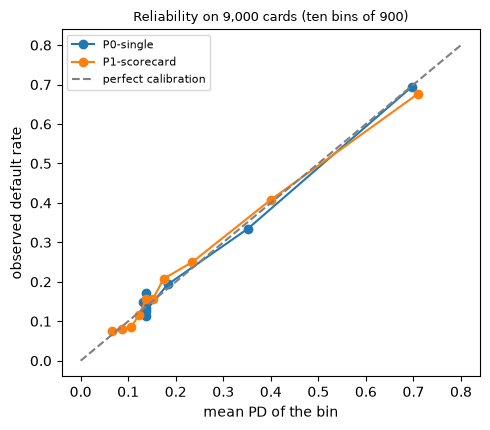

In [10]:
# Chi-square over grades and level test of the portfolio, from the committed grade table of each model
fig, ax = plt.subplots(figsize=(5, 4.4))
for rung in ("P0-single", "P1-scorecard"):
    grades = [g for g in rungs[rung]["grades"] if g["n"] > 0]
    n_g, d_g, pd_g = [g["n"] for g in grades], [g["d"] for g in grades], [g["pd"] for g in grades]
    chi = pd_chi2_grades(n_g, d_g, pd_g, policy=policy, model_id=rung, segment="portfolio")
    mean_pd = sum(n * p for n, p in zip(n_g, pd_g)) / sum(n_g)
    level = pd_jeffreys(sum(n_g), sum(d_g), mean_pd, policy=policy, model_id=rung, segment="portfolio")
    print("chi-square over grades, p and light:", rung, round(chi.p_value, 4), LIGHT[chi.light.value])
    print("level test of the portfolio, Jeffreys p:", rung, round(level.p_value, 4))
    bins_ = rungs[rung]["reliability"]
    ax.plot([b["pd"] for b in bins_], [b["dr"] for b in bins_], marker="o", label=rung)
ax.plot([0, 0.8], [0, 0.8], color="gray", linestyle="--", label="perfect calibration")
ax.set_xlabel("mean PD of the bin")
ax.set_ylabel("observed default rate")
ax.set_title("Reliability on 9,000 cards (ten bins of 900)", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

**Answer:** Yes, the fitted scorecard earns its variables, and the evidence is on cards the fit never saw. The fit sees only the 16,800 training cards: the three slices share one default rate (the spread is 3e-05), all 13 kept variables keep every bin above 5% of the cards (13 of 13) and follow their direction (13 of 13). The score is a plain sum: 650 of 650 point cells and 50 of 50 scores rebuild from raw inputs and cut points. Against the one-variable baseline, the engine gives on the rebuilt 9,000 held-out cards an AUC of 0.7586 for the scorecard against 0.6994 for `PAY_0` alone (committed 0.7587 and 0.6917) and a KS of 0.3956 against 0.3573. On the 50-card sample, the DeLong test rejects equal AUCs with a statistic of 2.55 and a p-value of 0.0107.

The ranking gain does not come with better calibration. The chi-square over grades is amber for the scorecard (p 0.0264) and green for the one-variable baseline (p 0.5982), and the level test is green for both (Jeffreys p 0.3095 and 0.2645). A model with four distinct PDs is easy to calibrate by grade and cannot rank well. The reliability curves show the scorecard tracking the diagonal over the whole range, with small departures in the middle, which notebook 03 follows up.

What this notebook does not show: the standard errors and p-values of the logistic step, which the committed record does not hold (the sign check of notebook 01 is their visible trace), a refit from the raw file (it needs the data root and the pipeline libraries), and any out-of-time behaviour: C01 is one snapshot of 2005, a limit that notebook 07 states as a finding.

## Summary

- The fit is leakage-safe by design: a stratified split with a fixed seed, bins and coefficients learned on the 16,800 training cards only, a separate calibration slice for the challengers and a locked holdout.
- The learned bins obey their constraints, which can be checked on the committed counts: at least 5% of the cards per bin and a default rate that follows its direction.
- A scorecard is auditable: from raw values and the cut points, the table of points rebuilds every score with no model object, and the spread of points per variable shows what it weighs.
- The engine's AUC, KS and DeLong tests rank the scorecard above the one-variable baseline, while the grade chi-square shows that better ranking is not better calibration.

**What to try next.** Replace `PAY_0` by `PAY_2` as the one-variable baseline in Step 5 and see how far the AUC falls; then continue with notebook 03, which runs the validation battery on the whole ladder of models.

## References

- Navas-Palencia, G. (2020), Optimal binning: mathematical programming formulation. https://arxiv.org/abs/2001.08025
- Siddiqi, N. (2017), Intelligent Credit Scoring, 2nd ed., Wiley. https://doi.org/10.1002/9781119282396
- DeLong, E. R., DeLong, D. M. and Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach, Biometrics 44(3). https://doi.org/10.2307/2531595
- Hanley, J. A. and McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
- This repository: `docs/guides/01_fetch-and-bake.md`, `docs/design/SDD.md` (the leakage-safe split of each case) and the pipeline's `data-pipeline/pipeline/model/scorecard.py`.